<a href="https://colab.research.google.com/github/abhinayakscs25-svg/BIS/blob/main/lab_7_parallel_cellular_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Image Shape: (512, 512)

Image Processing Completed
Execution Time: 0.6334 seconds


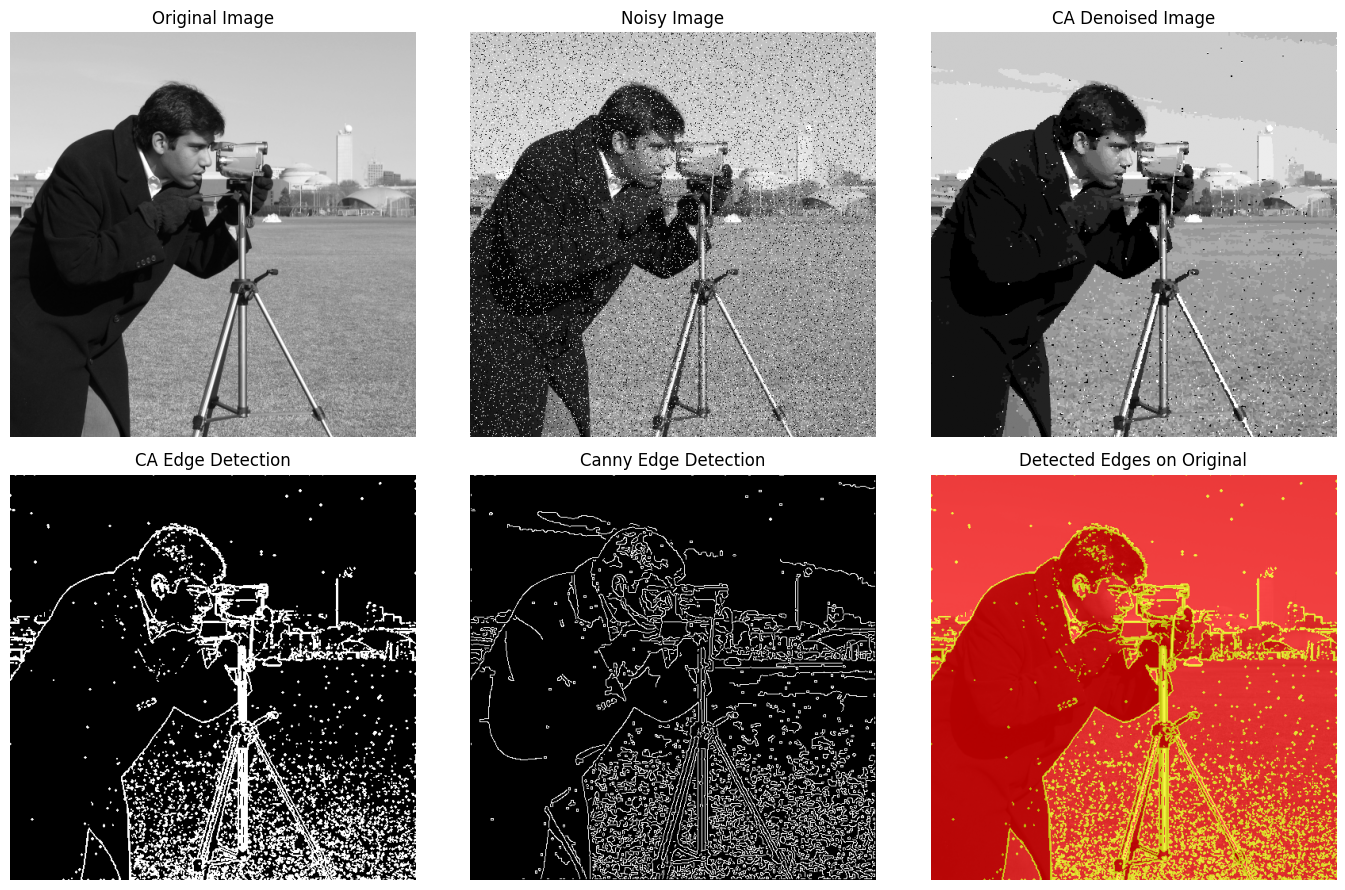

In [1]:

# PARALLEL CELLULAR AUTOMATA FOR IMAGE PROCESSING
# Noise Removal and Edge Detection

import numpy as np
import matplotlib.pyplot as plt
import time

from skimage import data, feature
from skimage.util import img_as_float

# 1. Load Image
image = img_as_float(data.camera())
print("Original Image Shape:", image.shape)

# 2. Add Salt and Pepper Noise
def add_noise(image):
    noisy = image.copy()
    noise = np.random.random(image.shape)

    noisy[noise < 0.05] = 0
    noisy[noise > 0.95] = 1

    return noisy

noisy_image = add_noise(image)

# 3. Convert Image into Cellular States
def quantize(image):
    return np.clip((image * 16).astype(int), 0, 15)

# 4. Cellular Automata Noise Removal
def ca_denoise(image, iterations=5):

    cells = quantize(image)

    for _ in range(iterations):

        padded = np.pad(cells, 1, mode='edge')

        neighbors = np.stack([
            padded[1:-1, 1:-1],  # Center
            padded[:-2, 1:-1],   # Top
            padded[2:, 1:-1],    # Bottom
            padded[1:-1, :-2],   # Left
            padded[1:-1, 2:]     # Right
        ])

        counts = np.stack([
            np.sum(neighbors == value, axis=0)
            for value in range(16)
        ])

        maximum = np.max(counts, axis=0)

        # Majority rule
        updated = np.argmax(counts, axis=0)

        # Preserve center state in case of a tie
        center = neighbors[0]
        center_count = counts[center, np.arange(cells.shape[0])[:, None],
                              np.arange(cells.shape[1])]

        updated[center_count == maximum] = center[center_count == maximum]

        cells = updated

    return cells / 15.0

# 5. Cellular Automata Edge Detection
def ca_edge_detection(image, threshold=2):

    cells = quantize(image)

    padded = np.pad(cells, 1, mode='edge')

    center = padded[1:-1, 1:-1]

    top = padded[:-2, 1:-1]
    bottom = padded[2:, 1:-1]
    left = padded[1:-1, :-2]
    right = padded[1:-1, 2:]

    # Edge rule:
    # If all neighboring differences are below threshold,
    # the cell becomes inactive.
    edge = (
        (np.abs(center - top) >= threshold) |
        (np.abs(center - bottom) >= threshold) |
        (np.abs(center - left) >= threshold) |
        (np.abs(center - right) >= threshold)
    )

    return edge.astype(int)

# 6. Execute Cellular Automata
start = time.time()

denoised = ca_denoise(noisy_image, iterations=5)

edges = ca_edge_detection(denoised, threshold=2)

end = time.time()

print("\nImage Processing Completed")
print("Execution Time:", round(end - start, 4), "seconds")

# 7. Compare with Canny Edge Detection
canny_edges = feature.canny(denoised, sigma=1.0)

# 8. Display Results
plt.figure(figsize=(14, 9))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(noisy_image, cmap='gray')
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(denoised, cmap='gray')
plt.title("CA Denoised Image")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(edges, cmap='gray')
plt.title("CA Edge Detection")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(image, cmap='gray')
plt.imshow(edges, cmap='autumn', alpha=0.7)
plt.title("Detected Edges on Original")
plt.axis("off")

plt.tight_layout()
plt.show()
